In [1]:
import pandas
import numpy 
import matplotlib.pyplot as plt 
from pathlib import Path 
import torchaudio 
import ffmpeg 
import librosa

Audio preprocessing completed
Sample rate: 22050
Duration: 15.84 seconds
Complex STFT shape: (513, 1365)
Magnitude shape: (513, 1365)
Model input shape: (513, 1365)


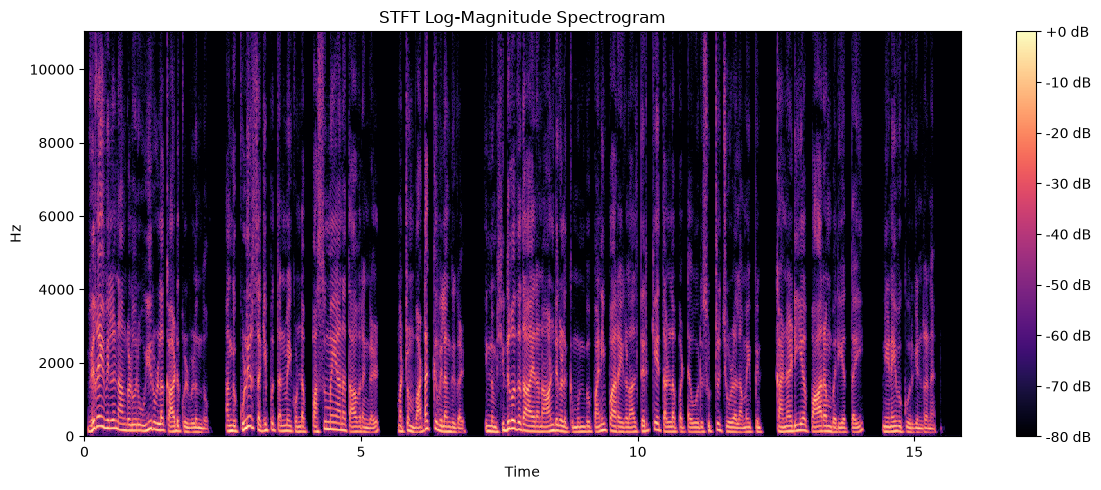

In [3]:

from pathlib import Path
import subprocess

import numpy as np
import librosa
import soundfile as sf
import torchaudio
import torch
import matplotlib.pyplot as plt


# Configuration
AUDIO_PATH = Path(r"D:\data_generate\tamil_speech_dataset\ai_audio\00000000.mp3")
OUTPUT_DIR = Path("processed_audio")

SR = 22050
N_FFT = 1024
HOP_LENGTH = 256
WIN_LENGTH = 1024
EPS = 1e-8

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not AUDIO_PATH.is_file():
    raise FileNotFoundError(AUDIO_PATH)

# 1. Convert audio to mono WAV at a standard sample rate
wav_path = OUTPUT_DIR / "standardized.wav"

subprocess.run(
    [
        "ffmpeg", "-y",
        "-i", str(AUDIO_PATH),
        "-vn", "-ac", "1",
        "-ar", str(SR),
        "-c:a", "pcm_s16le",
        str(wav_path),
    ],
    check=True,
    capture_output=True,
)

# 2. Read the audio
y, sr = sf.read(wav_path, dtype="float32")

if y.ndim > 1:
    y = y.mean(axis=1)

if len(y) < N_FFT:
    raise ValueError("Audio is too short for the selected FFT window.")

# 3. Apply STFT
stft_matrix = librosa.stft(
    y=y,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH,
    window="hann",
    center=True,
)

# 4. Extract magnitude and phase
magnitude = np.abs(stft_matrix)
phase = np.angle(stft_matrix)

# 5. Convert magnitude to log scale
log_magnitude = np.log1p(magnitude)

# 6. Normalize features
mean = log_magnitude.mean()
std = log_magnitude.std()

normalized_features = (
    log_magnitude - mean
) / max(std, EPS)

# 7. Save features
np.save(
    OUTPUT_DIR / "stft_complex.npy",
    stft_matrix,
)
np.save(
    OUTPUT_DIR / "stft_magnitude.npy",
    magnitude,
)
np.save(
    OUTPUT_DIR / "stft_phase.npy",
    phase,
)
np.save(
    OUTPUT_DIR / "stft_normalized.npy",
    normalized_features.astype(np.float32),
)

# 8. Convert features to PyTorch tensors
features_tensor = torch.from_numpy(
    normalized_features.astype(np.float32)
)

print("Audio preprocessing completed")
print("Sample rate:", sr)
print("Duration:", round(len(y) / sr, 2), "seconds")
print("Complex STFT shape:", stft_matrix.shape)
print("Magnitude shape:", magnitude.shape)
print("Model input shape:", tuple(features_tensor.shape))

# 9. Plot the log-magnitude spectrogram
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    librosa.amplitude_to_db(
        magnitude,
        ref=np.max,
    ),
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="linear",
)

plt.colorbar(format="%+2.0f dB")
plt.title("STFT Log-Magnitude Spectrogram")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "stft_spectrogram.png", dpi=150)
plt.show()
